# PySpark FP-Growth: equivalence and measured performance

We use the frozen 437 state-year transactions and the support/confidence settings from Python FP-Growth. Spark supplies single-item consequents, so rule comparison uses the same family on both sides. We verify exact itemset identities/counts and rule identities/metrics before interpreting performance.

The benchmark uses a two-core local Spark session, cached input, one warm-up per engine/scenario and three measured repetitions in alternating engine order. Both implementations materialize itemsets and rules. Disk exports and equivalence checks are outside the warmed timed scope. This is a local small-data comparison, not a distributed-cluster scalability experiment. No second Spark algorithm runs here.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/prison-mpl")
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from src.mining.spark_fp_growth import run_spark_fp_growth
sns.set_theme(style="whitegrid")

## Execute Spark mining, validate outputs and benchmark

The source uses Spark ML's `FPGrowth(itemsCol="items", numPartitions=2)` and explicit-schema JSON input. It caches/materializes the same transaction arrays, collects both `freqItemsets` and `associationRules`, and compares all twelve parameter settings with Python. The local session is stopped in a `finally` block. The saved environment/protocol records software, hardware and Spark configuration.

Startup, input preparation and the first cold baseline job are recorded separately. Warmed timing ratios do not include these costs. Memory samples record process RSS footprints, not isolated algorithm allocations.

In [2]:
import warnings

# This JSON/row pipeline does not use Spark's pandas integration.
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message=r"PySpark does not yet fully support pandas >= 3\.0\.0\..*",
        category=FutureWarning,
    )
    summary = run_spark_fp_growth(ROOT, repetitions=3)
TABLES = ROOT / "results/tables/spark_fp_growth"
BENCHMARKS = ROOT / "results/benchmarks/spark_fp_growth"
PLOTS = ROOT / "results/plots/spark_fp_growth"
PLOTS.mkdir(parents=True, exist_ok=True)
equivalence = pd.read_csv(TABLES / "equivalence.csv")
timings = pd.read_csv(BENCHMARKS / "timing_runs.csv")
comparison = pd.read_csv(BENCHMARKS / "timing_summary.csv")
display(equivalence)
display(comparison)
print("Spark startup seconds:", summary["startup_seconds"])
print("Cold baseline end-to-end seconds:", summary["cold_baseline_end_to_end_seconds"])

,min_support,min_count,min_confidence,itemsets,rules,equivalent
0,0.05,22,0.6,166,16,True
1,0.05,22,0.7,166,4,True
2,0.05,22,0.8,166,0,True
3,0.10,44,0.6,75,1,True
4,0.10,44,0.7,75,0,True
5,0.10,44,0.8,75,0,True
6,0.15,66,0.6,23,0,True
7,0.15,66,0.7,23,0,True
8,0.15,66,0.8,23,0,True
9,0.20,88,0.6,15,0,True


,min_support,min_confidence,repetitions,python_median_seconds,spark_median_seconds,python_min_seconds,python_max_seconds,spark_min_seconds,spark_max_seconds,speedup_python_over_spark,spark_over_python_ratio
0,0.05,0.7,3,0.004644,0.186462,0.004370,0.004880,0.176845,0.217726,0.024908,40.147329
1,0.10,0.7,3,0.003667,0.184746,0.003107,0.003669,0.176583,0.217196,0.019849,50.379927


Spark startup seconds: 2.793779473999166
Cold baseline end-to-end seconds: 5.372720579998713


## Interpret the measured timings

Speedup is Python median time divided by Spark median time. A value below one means Spark is slower. We retain each observation and report minimum/maximum ranges rather than claiming a stable speedup from a single run. The dataset contains only 437 short transactions; scheduling, JVM and collection overhead may dominate.

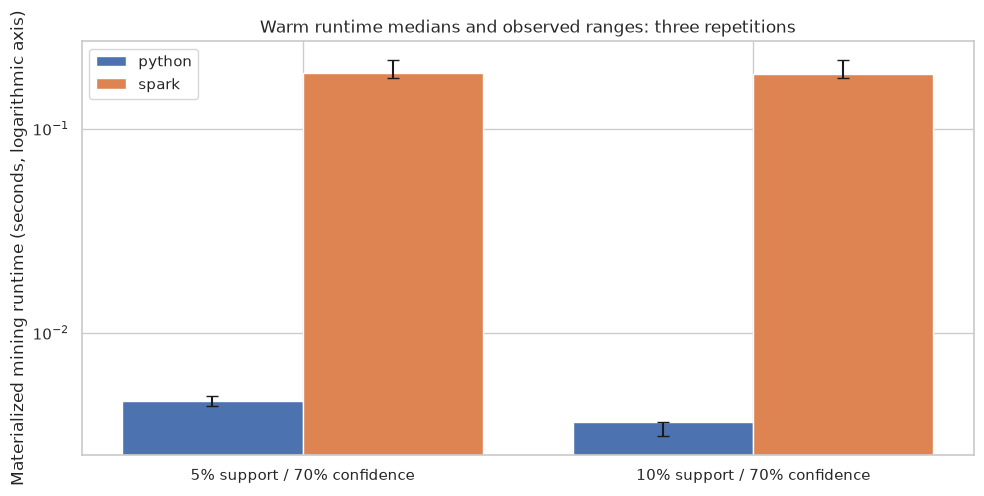

Support 5%: Python 0.004644s; Spark 0.186462s; speedup 0.024908x.
Support 10%: Python 0.003667s; Spark 0.184746s; speedup 0.019849x.


In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
positions = np.arange(len(comparison))
for offset, engine in [(-.2, "python"), (.2, "spark")]:
    medians = comparison[f"{engine}_median_seconds"].to_numpy()
    lower = medians - comparison[f"{engine}_min_seconds"].to_numpy()
    upper = comparison[f"{engine}_max_seconds"].to_numpy() - medians
    ax.bar(positions + offset, medians, width=.4, yerr=np.vstack([lower, upper]),
           capsize=4, label=engine)
ax.set_yscale("log")
ax.set_xticks(positions, [f"{value:.0%} support / 70% confidence" for value in comparison.min_support])
ax.set_ylabel("Materialized mining runtime (seconds, logarithmic axis)")
ax.set_title("Warm runtime medians and observed ranges: three repetitions")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "warm_runtime_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
for row in comparison.itertuples():
    print(f"Support {row.min_support:.0%}: Python {row.python_median_seconds:.6f}s; Spark {row.spark_median_seconds:.6f}s; speedup {row.speedup_python_over_spark:.6f}x.")

## Inspect repetitions and memory scope

,engine,min_support,min_confidence,repetition,warmup,seconds,rss_baseline_mib,sampled_peak_rss_mib,itemsets,rules
0,python,0.10,0.7,0,True,0.003299,243.453125,243.699219,75,0
1,spark,0.10,0.7,0,True,0.240662,853.632812,873.296875,75,0
2,python,0.10,0.7,1,False,0.003667,244.164062,244.359375,75,0
3,spark,0.10,0.7,1,False,0.184746,873.621094,882.910156,75,0
4,spark,0.10,0.7,2,False,0.217196,882.914062,900.171875,75,0
5,python,0.10,0.7,2,False,0.003669,244.539062,244.699219,75,0
6,python,0.10,0.7,3,False,0.003107,244.699219,244.910156,75,0
7,spark,0.10,0.7,3,False,0.176583,897.441406,902.808594,75,0
8,python,0.05,0.7,0,True,0.004740,244.996094,245.378906,166,4
9,spark,0.05,0.7,0,True,0.223361,903.222656,915.792969,166,4


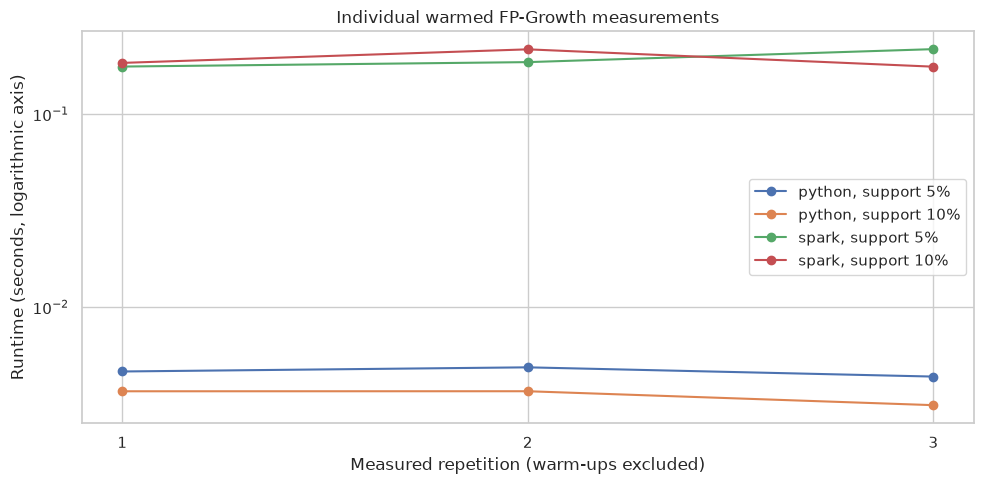

In [4]:
display(timings)
fig, ax = plt.subplots(figsize=(10, 5))
for (engine, support), group in timings[~timings.warmup].groupby(["engine", "min_support"]):
    ax.plot(group.repetition, group.seconds, marker="o", label=f"{engine}, support {support:.0%}")
ax.set_yscale("log")
ax.set_xticks([1, 2, 3])
ax.set_xlabel("Measured repetition (warm-ups excluded)")
ax.set_ylabel("Runtime (seconds, logarithmic axis)")
ax.set_title("Individual warmed FP-Growth measurements")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "timing_repetitions.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

RSS is sampled every 20 ms. Python rows include the Python driver only; Spark rows include the driver and its child/JVM processes. Retained heaps, shared pages, sampling gaps and the active Spark session prevent interpreting these footprints as isolated algorithm allocations. No memory-efficiency claim is made.

## Actual itemsets and rules

In [5]:
display(pd.read_csv(TABLES / "itemsets_s0p05_c0p70.csv").head(15))
display(pd.read_csv(TABLES / "rules_s0p05_c0p70.csv"))
assert equivalence.equivalent.all() and len(equivalence) == 12
assert summary["input_roundtrip_equivalent"]
from src.preprocessing.cleaning import sha256
for item in summary["inputs"]:
    assert sha256(ROOT / item["file"]) == item["sha256"]
print("Verified input equivalence, all twelve output settings and unchanged prepared files.")

,items,support_count,support
0,"[""age_18_30_share=lower_tertile""]",146,0.334096
1,"[""age_18_30_share=middle_tertile""]",145,0.331808
2,"[""age_18_30_share=upper_tertile""]",146,0.334096
3,"[""female_share=lower_tertile""]",146,0.334096
4,"[""female_share=middle_tertile""]",145,0.331808
5,"[""female_share=upper_tertile""]",146,0.334096
6,"[""illiterate_share=lower_tertile""]",147,0.336384
7,"[""illiterate_share=middle_tertile""]",144,0.329519
8,"[""illiterate_share=upper_tertile""]",146,0.334096
9,"[""occupancy_ratio=over_100_to_150pct""]",160,0.366133


,antecedents,consequents,support,confidence,lift
0,"[""age_18_30_share=upper_tertile"", ""illiterate_...","[""occupancy_ratio=within_capacity""]",0.093822,0.732143,1.777480
1,"[""female_share=middle_tertile"", ""occupancy_rat...","[""illiterate_share=upper_tertile""]",0.064073,0.736842,2.205479
2,"[""female_share=upper_tertile"", ""illiterate_sha...","[""occupancy_ratio=within_capacity""]",0.077803,0.739130,1.794444
3,"[""illiterate_share=lower_tertile"", ""undertrial...","[""occupancy_ratio=within_capacity""]",0.075515,0.733333,1.780370


Verified input equivalence, all twelve output settings and unchanged prepared files.


## Conclusions and limitations

Read the printed measurements and [Phase 9 report](../report/spark_fp_growth.md) for the observed outcome. A successful Spark implementation does not itself establish performance enhancement. This experiment uses one local host, two Spark threads, cached tiny inputs and three repetitions; it cannot establish big-data scaling. Python generates its complete rule family before restricting to single-item consequents, while Spark natively uses that restriction. No Python-worker UDF compatibility or second Spark algorithm is established here.

Sources: [Spark FP-Growth](https://spark.apache.org/docs/latest/ml-frequent-pattern-mining.html), [Spark installation](https://spark.apache.org/docs/latest/api/python/getting_started/install.html), [Python FP-Growth results](../report/fp_growth.md). The second Spark experiment is documented in [08_PySpark_KMedoids.ipynb](08_PySpark_KMedoids.ipynb).